In [10]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

RAIZ = Path.cwd().parent
FIG = RAIZ / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(RAIZ / "data" / "processed" / "concreto_limpio.csv")
cols = ["cemento", "escoria", "ceniza", "agua", "superplast",
        "agr_grueso", "agr_fino", "edad", "resistencia"]

print(df.shape)
print("id_mezcla presente:", "id_mezcla" in df.columns)

(1005, 10)
id_mezcla presente: True


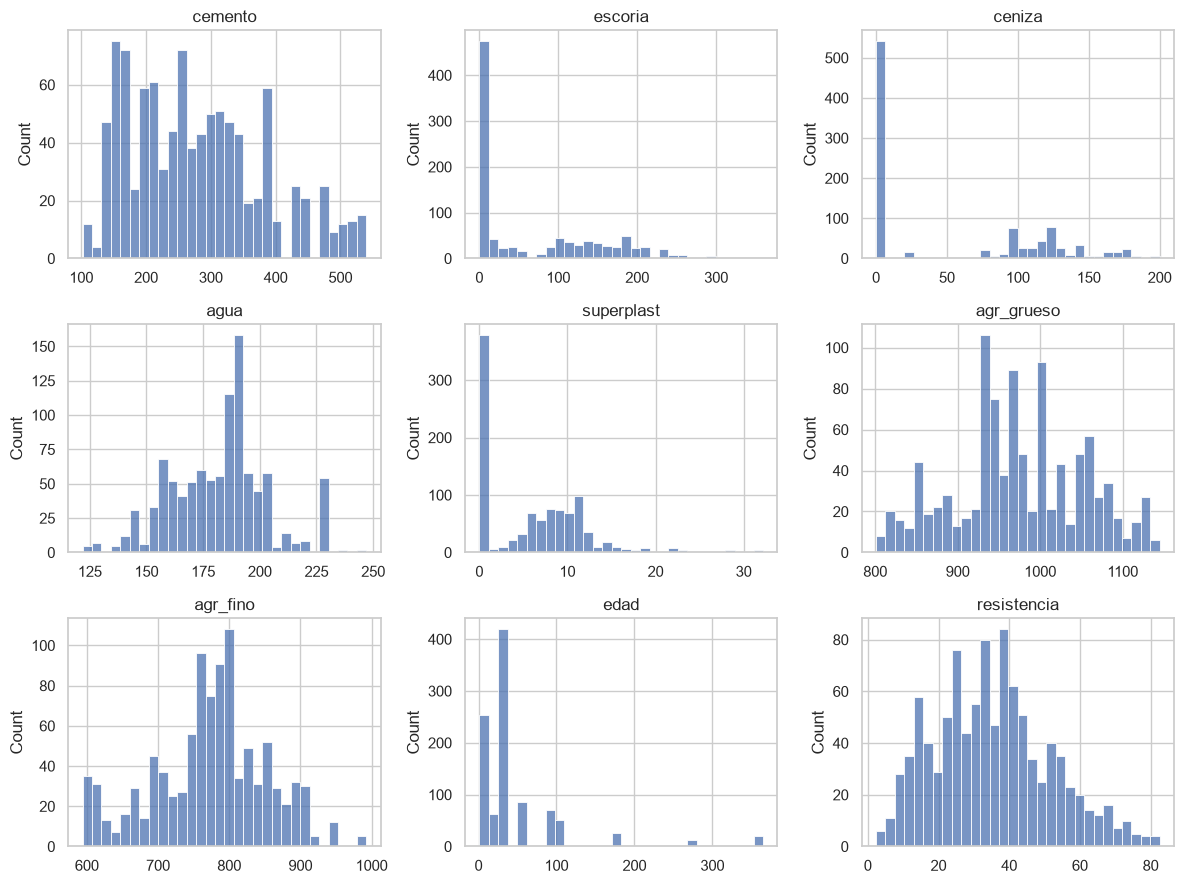

In [11]:
fig, axes = plt.subplots(3, 3, figsize=(12, 9))
for ax, col in zip(axes.ravel(), cols):
    sns.histplot(df[col], bins=30, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
plt.tight_layout()
plt.savefig(FIG / "01_distribuciones.png", dpi=150)
plt.show()

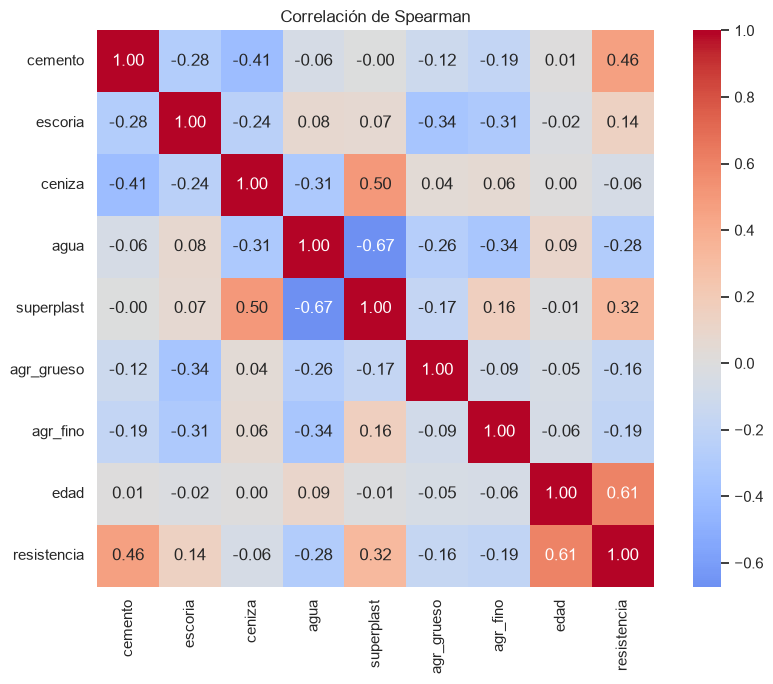

agua         -0.284250
agr_fino     -0.193290
agr_grueso   -0.162872
ceniza       -0.056319
escoria       0.140337
superplast    0.321763
cemento       0.461406
edad          0.605411
Name: resistencia, dtype: float64

In [12]:
corr = df[cols].corr(method="spearman")

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlación de Spearman")
plt.tight_layout()
plt.savefig(FIG / "02_correlaciones.png", dpi=150)
plt.show()

corr["resistencia"].drop("resistencia").sort_values()

In [13]:
df["ligantes"] = df["cemento"] + df["escoria"] + df["ceniza"]
df["a_c"] = df["agua"] / df["cemento"]
df["a_lig"] = df["agua"] / df["ligantes"]
df["log_edad"] = np.log(df["edad"])

nuevas = ["a_c", "a_lig", "ligantes", "log_edad"]
df[nuevas + ["resistencia"]].corr(method="spearman")["resistencia"].drop("resistencia")

a_c        -0.503996
a_lig      -0.590790
ligantes    0.584315
log_edad    0.605411
Name: resistencia, dtype: float64

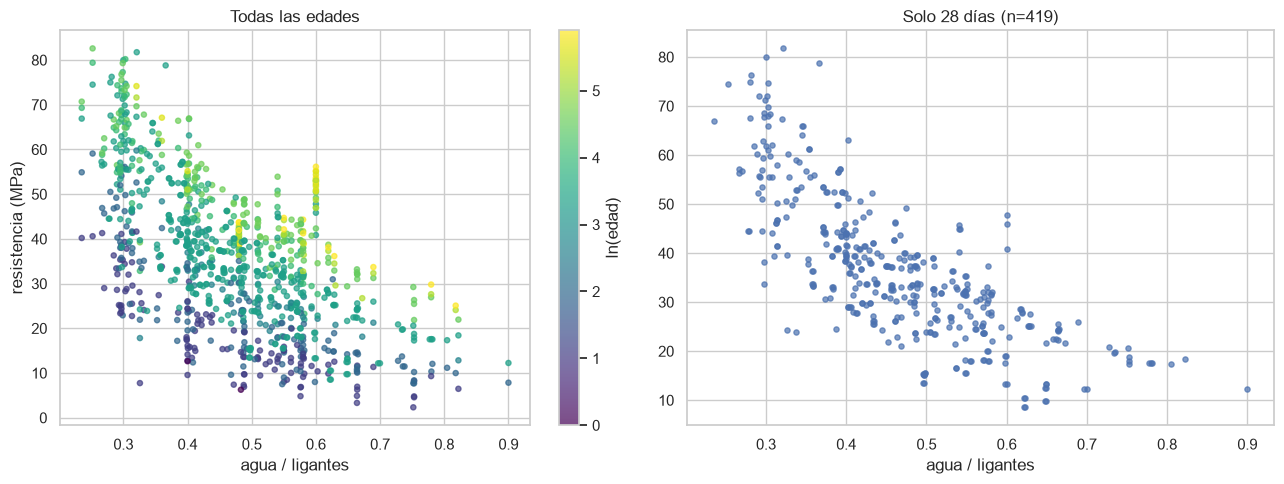

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sc = axes[0].scatter(df["a_lig"], df["resistencia"],
                     c=df["log_edad"], cmap="viridis", s=14, alpha=0.7)
axes[0].set_xlabel("agua / ligantes")
axes[0].set_ylabel("resistencia (MPa)")
axes[0].set_title("Todas las edades")
fig.colorbar(sc, ax=axes[0], label="ln(edad)")

d28 = df[df["edad"] == 28]
axes[1].scatter(d28["a_lig"], d28["resistencia"], s=14, alpha=0.7)
axes[1].set_xlabel("agua / ligantes")
axes[1].set_title(f"Solo 28 días (n={len(d28)})")

plt.tight_layout()
plt.savefig(FIG / "03_abrams.png", dpi=150)
plt.show()

Mezclas con 6 o más edades: 18


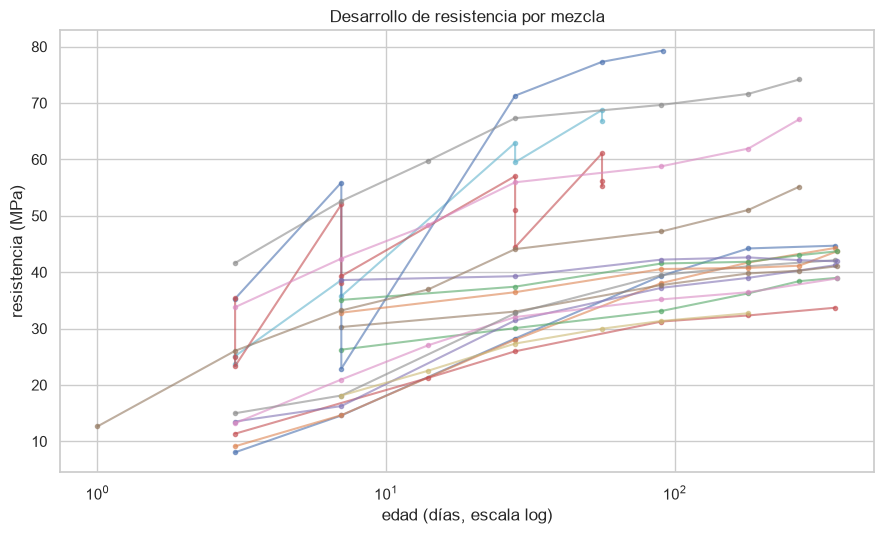

In [15]:
tam = df.groupby("id_mezcla")["edad"].transform("size")
varias = df[tam >= 6]
print("Mezclas con 6 o más edades:", varias["id_mezcla"].nunique())

plt.figure(figsize=(9, 5.5))
for _, g in varias.groupby("id_mezcla"):
    g = g.sort_values("edad")
    plt.plot(g["edad"], g["resistencia"], marker="o", ms=3, alpha=0.6)
plt.xscale("log")
plt.xlabel("edad (días, escala log)")
plt.ylabel("resistencia (MPa)")
plt.title("Desarrollo de resistencia por mezcla")
plt.tight_layout()
plt.savefig(FIG / "04_curvas_edad.png", dpi=150)
plt.show()

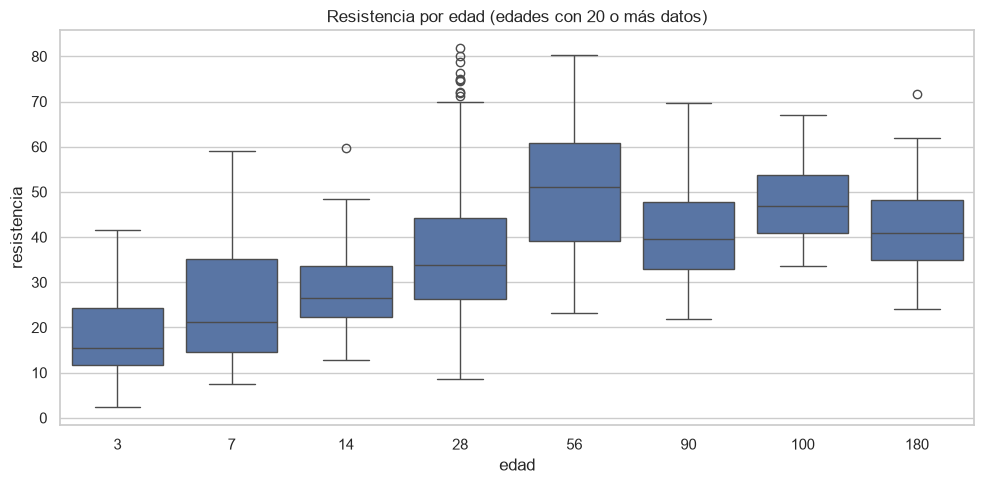

In [16]:
conteo = df["edad"].value_counts()
edades = conteo[conteo >= 20].index.sort_values()

plt.figure(figsize=(10, 5))
sns.boxplot(data=df[df["edad"].isin(edades)], x="edad", y="resistencia")
plt.title("Resistencia por edad (edades con 20 o más datos)")
plt.tight_layout()
plt.savefig(FIG / "05_boxplot_edad.png", dpi=150)
plt.show()

In [17]:
cols_ver = ["cemento", "agua", "a_lig", "edad", "resistencia"]
print("Mayores resistencias:")
display(df.nlargest(5, "resistencia")[cols_ver])
print("Menores resistencias:")
display(df.nsmallest(5, "resistencia")[cols_ver])

Mayores resistencias:


,cemento,agua,a_lig,edad,resistencia
158,389.9,145.9,0.252030,91,82.60
357,315.0,145.0,0.320796,28,81.75
137,323.7,183.8,0.303050,56,80.20
0,540.0,162.0,0.300000,28,79.99
141,389.9,145.9,0.252030,56,79.40


Menores resistencias:


,cemento,agua,a_lig,edad,resistencia
664,108.3,203.5,0.751755,3,2.33
681,122.6,203.5,0.663948,3,3.32
628,102.0,192.0,0.752941,3,4.57
644,153.0,192.0,0.752941,3,4.78
693,141.3,203.5,0.575998,3,4.83


In [18]:
d28 = df[df["edad"] == 28]
pend, interc = np.polyfit(d28["a_lig"], np.log(d28["resistencia"]), 1)
pred = np.exp(interc + pend * d28["a_lig"])

res = d28["resistencia"] - pred
r2 = 1 - (res**2).sum() / ((d28["resistencia"] - d28["resistencia"].mean())**2).sum()

print(f"ln(f) = {interc:.3f} + ({pend:.3f}) * (agua/ligantes)")
print(f"R² (escala MPa): {r2:.2f}")
print(f"RMSE: {np.sqrt((res**2).mean()):.1f} MPa")

ln(f) = 4.806 + (-2.780) * (agua/ligantes)
R² (escala MPa): 0.62
RMSE: 8.8 MPa


## Conclusiones del análisis exploratorio

- La resistencia crece con edad (ρ=0.61) y cemento (ρ=0.46) y decrece con el agua (ρ=-0.28).
- La relación agua/ligantes reproduce la ley de Abrams a 28 días (curva decreciente).
- A igual agua/ligantes hay mucha dispersión: otras variables y diferencias entre laboratorios.
- Las medianas por edad no son monótonas (90 y 180 días bajan) por efecto de composición entre estudios, no por física.
- Los valores extremos son físicamente plausibles; no se eliminan.
- Decisión: usar agua/ligantes y ln(edad) como variables derivadas y validar por grupos de mezcla.
- agua/ligantes (ρ=-0.59) y ligantes totales (ρ=+0.58) correlacionan mucho más con la resistencia que el agua (-0.28) o el cemento (+0.46) por separado.
- Ninguna mezcla pierde resistencia con la edad; las pendientes varían entre mezclas (interacción edad × dosificación).
- Réplicas de una misma mezcla y edad difieren en varios MPa: ruido de ensayo que fija un límite al desempeño de cualquier modelo.
- Línea base de Abrams a 28 días: ln(f) = 4.806 - 2.780·(agua/ligantes); R²=0.62, RMSE=8.8 MPa (en la muestra, no validada).